### IND320 project work part 2
Name: Mina Johanne Askerød <br>
Date: .11.2026 <br>
GitHub link: https://github.com/Minajohanne/IND320_project_Minajohanne <br>
Streamlit link: https://ind320projectminajohanne.streamlit.app/<br>
Recording link: 


#### Import packages 

In [35]:
import geopandas as gpd
import openmeteo_requests
import pandas as pd
import requests_cache
from retry_requests import retry
import time 
from openmeteo_requests.Client import OpenMeteoRequestsError
import matplotlib.pyplot as plt
from scipy.fft import dct, idct
import numpy as np 
import scipy.stats as stats
from sklearn.neighbors import LocalOutlierFactor
from matplotlib.figure import Figure



Randomly sample 1000 locations in each region to use for weather data download.

In [ ]:
# Read shapefiles
gdf_nve = gpd.read_file("../data/NVE_Region") # precipitation areas 
gdf_el = gpd.read_file("../data/Budområder") # electricity areas 

In [3]:

def generate_coordinates(
    gdf: gpd.GeoDataFrame,
    region_column: str,
    K: int = 1000
) -> dict[str, list[tuple[float, float]]]:
    """
    Generate K random longitude-latitude coordinate pairs within each region.

    The geometries are projected to EPSG:25833 before sampling to ensure
    that points are sampled using a projected coordinate system.
    The sampled points are then converted to WGS84 (EPSG:4326).

    Args:
        gdf (gpd.GeoDataFrame): GeoDataFrame containing region geometries.
        region_column (str): Name of the column containing region names.
        K (int): Number of random points to generate per region.
            Defaults to 1000.

    Returns:
        dict[str, list[tuple[float, float]]]: Dictionary mapping each
        region name to a list of (longitude, latitude) coordinate pairs.
    """

    # Project geometries to a coordinate system using metres
    gdf_projected = gdf.to_crs(epsg=25833)

    # Generate K random points within each region geometry
    points = gdf_projected.geometry.sample_points(
        size=K,
        random_state=42
    )

    # Convert sampled points to WGS84 (longitude, latitude)
    points_wgs84 = points.to_crs(epsg=4326)

    region_coordinates: dict[str, list[tuple[float, float]]] = {}

    # Extract longitude and latitude for each sampled point
    for i, multipoint in points_wgs84.items():
        region_name = gdf.loc[i, region_column]

        coordinates = [
            (point.x, point.y)
            for point in multipoint.geoms
        ]

        region_coordinates[region_name] = coordinates

    return region_coordinates


In [4]:
# Generate coordinates for NVE regions
nve_coordinates = generate_coordinates(
    gdf_nve,
    region_column="REGION"
)

# Generate coordinates for electricity areas
el_coordinates = generate_coordinates(
    gdf_el,
    region_column="budomr"
)

In [8]:
print(f"Precipitation areas: {nve_coordinates.keys()}")
print(f"Electricity areas: {el_coordinates.keys()}")

Precipitation areas: dict_keys(['RV', 'RM', 'RN', 'RÃ\x98', 'RS'])
Electricity areas: dict_keys(['NO 1', 'NO 2', 'NO 3', 'NO 4', 'NO 5'])


hourly historical reanalysis data using the ERA5 model 

function for the API download task that takes a region identifier plus a time interval as input, looks up the corresponding of list of pairs

In [6]:
def get_weather_data(region: str, start_date: str, end_date: str) -> pd.DataFrame:
    """
    Download hourly historical weather data from the Open-Meteo API using the ERA5 model.

    Retrieves temperature and precipitation data for 1000 randomly sampled
    locations within the specified region and calculates the hourly average
    across all locations.

    Args:
        region (str): Region identifier, e.g. "NO 3".
        start_date (str): Start date in YYYY-MM-DD format.
        end_date (str): End date in YYYY-MM-DD format.

    Returns:
        pd.DataFrame: DataFrame containing hourly timestamps, average temperature
        (°C), and average precipitation (mm) for the selected region.
    """
    # Setup Open-Meteo API client
    cache_session = requests_cache.CachedSession(".cache", expire_after=-1)
    retry_session = retry(cache_session, retries=5, backoff_factor=0.2)
    openmeteo = openmeteo_requests.Client(session=retry_session)

    # Get coordinates for the selected region
    lon = [lon for lon, lat in el_coordinates[region]]
    lat = [lat for lon, lat in el_coordinates[region]]

    # API URL
    url = "https://archive-api.open-meteo.com/v1/archive"

    # Store data for each location
    dataframes = []
    batch_size = 10

    # Download weather data in batches
    for i in range(0, len(lat), batch_size):

        lat_batch = lat[i:i + batch_size]
        lon_batch = lon[i:i + batch_size]

        # API parameters
        params = {
            "latitude": lat_batch,
            "longitude": lon_batch,
            "start_date": start_date,
            "end_date": end_date,
            "hourly": ["temperature_2m", "precipitation"],
            "models": "era5",
        }

        # Download weather data

        # Download weather data
        while True:
            try:
                responses = openmeteo.weather_api(url, params=params)
                break

            except OpenMeteoRequestsError as e:
                if "Minutely API request limit exceeded" in str(e):
                    print("API limit reached. Waiting 60 seconds...")
                    time.sleep(60)
                else:
                    raise

        # Process data for each location
        for response in responses:
            hourly = response.Hourly()

            temperature = hourly.Variables(0).ValuesAsNumpy()
            precipitation = hourly.Variables(1).ValuesAsNumpy()

            dates = pd.date_range(
                start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
                end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
                freq=pd.Timedelta(seconds=hourly.Interval()),
                inclusive="left"
            )

            df = pd.DataFrame({
                "date": dates,
                "temperature_2m": temperature,
                "precipitation": precipitation
            })

            dataframes.append(df)

        print(f"Downloaded {min(i + batch_size, len(lat))}/{len(lat)} locations")

    # Combine all locations
    weather_data = pd.concat(dataframes, ignore_index=True)

    # Calculate hourly averages across the region
    regional_average = (
        weather_data
        .groupby("date")[["temperature_2m", "precipitation"]]
        .mean()
        .reset_index()
    )

    return regional_average


# reference: https://open-meteo.com/en/docs/historical-weather-api?models=era5&hourly=temperature_2m,precipitation&daily=temperature_2m_mean (27.10.2026)

In [ ]:
weather_no3 = get_weather_data(
    region="NO 3",
    start_date="2024-01-01",
    end_date="2024-12-31"
)

weather_no3.head()

Downloaded 10/1000 locations
Downloaded 20/1000 locations
Downloaded 30/1000 locations
Downloaded 40/1000 locations
Downloaded 50/1000 locations
Downloaded 60/1000 locations
Downloaded 70/1000 locations
Downloaded 80/1000 locations
Downloaded 90/1000 locations
Downloaded 100/1000 locations
Downloaded 110/1000 locations
Downloaded 120/1000 locations
Downloaded 130/1000 locations
Downloaded 140/1000 locations
Downloaded 150/1000 locations
Downloaded 160/1000 locations
Downloaded 170/1000 locations
Downloaded 180/1000 locations
Downloaded 190/1000 locations
Downloaded 200/1000 locations
Downloaded 210/1000 locations
Downloaded 220/1000 locations
Downloaded 230/1000 locations
Downloaded 240/1000 locations
Downloaded 250/1000 locations
Downloaded 260/1000 locations
Downloaded 270/1000 locations
Downloaded 280/1000 locations
Downloaded 290/1000 locations
Downloaded 300/1000 locations
Downloaded 310/1000 locations
Downloaded 320/1000 locations
Downloaded 330/1000 locations
Downloaded 340/1000

,date,temperature_2m,precipitation
0,2024-01-01 00:00:00+00:00,-3.745238,0.0044
1,2024-01-01 01:00:00+00:00,-3.879938,0.0037
2,2024-01-01 02:00:00+00:00,-3.844888,0.0037
3,2024-01-01 03:00:00+00:00,-3.866238,0.0037
4,2024-01-01 04:00:00+00:00,-3.814838,0.0034


In [19]:
weather_no3.shape

(8784, 3)

Plot of the average precipitation as a function of time.

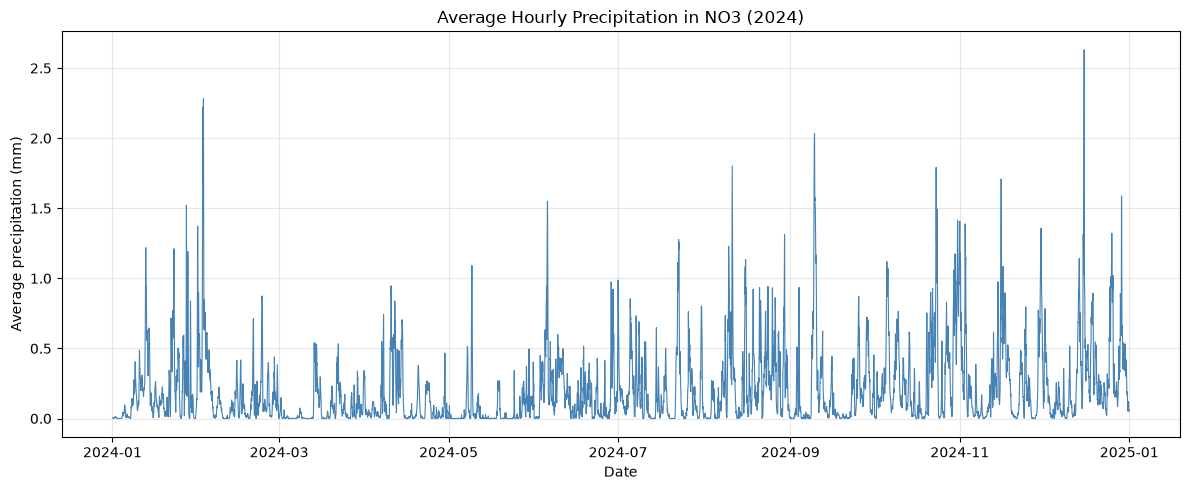

In [10]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    weather_no3["date"],
    weather_no3["precipitation"],
    color="steelblue",
    linewidth=0.8
)

ax.set_title("Average Hourly Precipitation in NO3 (2024)")
ax.set_xlabel("Date")
ax.set_ylabel("Average precipitation (mm)")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

High pass filtering (remover low frequencies, trends or baselines. Focusing on rapid changes or anomalies) of the precipitation using the discrete cosine transform -> seasonally adjusted temperature variations 

In [14]:
# Extract precipitation data
precipitation = weather_no3["precipitation"].to_numpy()

# Discrete Cosine Transform
dct_signal = dct(precipitation, type=1, norm="forward")

# Frequency axis (cycles per hour)
N = len(precipitation)
dt = 1  # Hourly observations
W = np.linspace(0, 1 / (2 * dt), N)

# High-pass filter: remove frequencies below cutoff
cutoff = 1 / (24 * 7)  # Remove variations slower than approximately 7 days

filtered_dct = dct_signal.copy()
filtered_dct[W < cutoff] = 0

# Inverse DCT to reconstruct the filtered signal
filtered_precipitation = idct(filtered_dct, type=1, norm="forward")

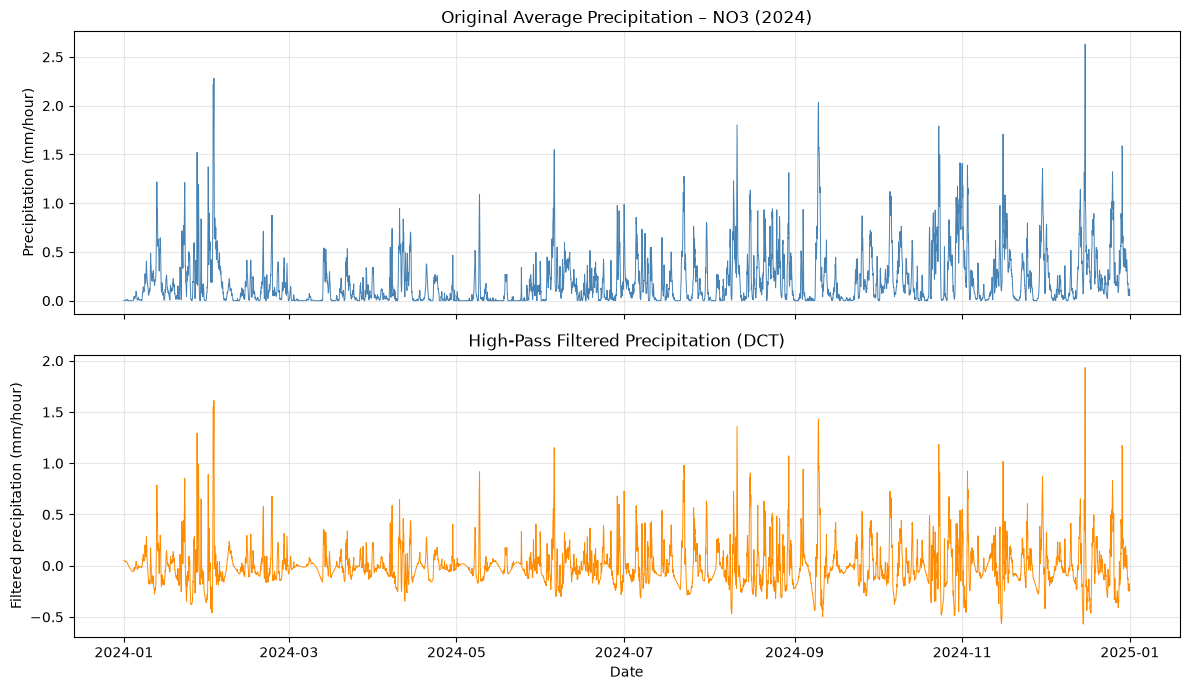

In [15]:
fig, axs = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Original precipitation
axs[0].plot(
    weather_no3["date"],
    precipitation,
    color="steelblue",
    linewidth=0.7
)
axs[0].set_title("Original Average Precipitation – NO3 (2024)")
axs[0].set_ylabel("Precipitation (mm/hour)")
axs[0].grid(alpha=0.3)

# High-pass filtered precipitation
axs[1].plot(
    weather_no3["date"],
    filtered_precipitation,
    color="darkorange",
    linewidth=0.7
)
axs[1].set_title("High-Pass Filtered Precipitation (DCT)")
axs[1].set_xlabel("Date")
axs[1].set_ylabel("Filtered precipitation (mm/hour)")
axs[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

The Discrete Cosine Transform (DCT) was used to apply a high-pass filter to the average hourly precipitation data for NO3 in 2024. DCT transforms the precipitation time series from the time domain into the frequency domain, making it possible to separate slow and rapid variations in the data.

Low frequencies represent changes that occur over longer periods, while high frequencies represent faster changes, such as short-term precipitation events. To apply the high-pass filter, a cutoff frequency corresponding to a period of approximately seven days was selected. The frequency components below this cutoff were set to zero, removing variations occurring over longer timescales. The inverse DCT (IDCT) was then used to transform the filtered data back into the time domain.

Comparing the original and filtered precipitation plots, we can see that the filtered signal still contains the short-term precipitation peaks, while the slower variations have been reduced. The filtered signal also fluctuates around zero and contains some negative values. This is expected because the filtered values no longer represent actual precipitation amounts, but rather the remaining variations after the low-frequency components have been removed.

Overall, the high-pass filter makes it easier to study short-term changes in precipitation by reducing the influence of slower variations in the original time series.

Adding curves to the plot indicating statistical process control boundaries between inliers and outliers (calculate the boundaries using SATV ??) 

checking wether the data are normaldistributed (assumption of SPC)

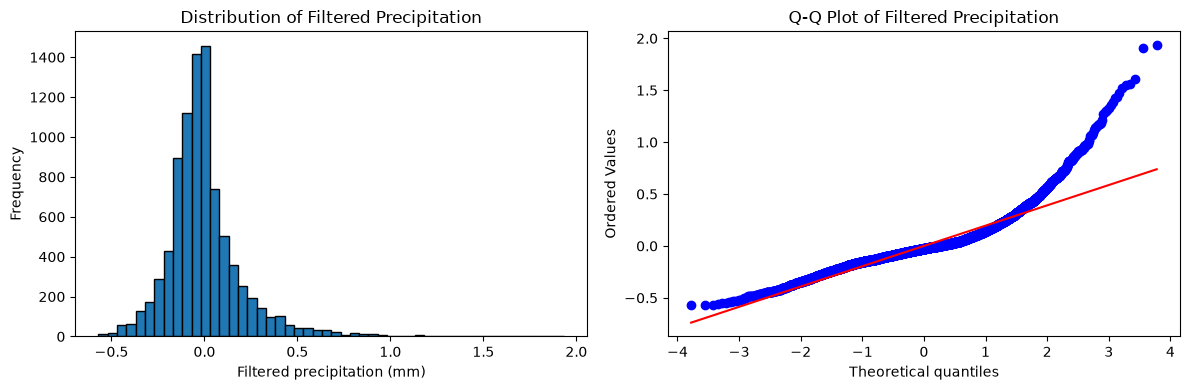

In [22]:
signal = np.asarray(filtered_precipitation)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram
axes[0].hist(signal, bins=50, edgecolor="black")
axes[0].set_title("Distribution of Filtered Precipitation")
axes[0].set_xlabel("Filtered precipitation (mm)")
axes[0].set_ylabel("Frequency")

# Q-Q plot
stats.probplot(signal, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q Plot of Filtered Precipitation")

plt.tight_layout()
plt.show()

The histogram and Q-Q plot indicate that the high-pass filtered precipitation data are not normally distributed. The distribution is right-skewed, with most observations concentrated around zero and a long tail towards higher values. The Q-Q plot also shows substantial deviations from the theoretical normal distribution, particularly in the upper tail.

This is relevant for the SPC analysis because the MAD scaling factor of 1.4826 assumes a normal distribution when estimating the standard deviation. Although MAD is robust to extreme observations, the resulting control limits should be interpreted with caution due to the skewed distribution.

In [ ]:
# High-pass filtered precipitation
signal = np.asarray(filtered_precipitation)

# Robust statistics estimated from the whole year
median = np.median(signal)
mad = np.median(np.abs(signal - median)) # mad -> absolute deviations from the median value 

# Estimate standard deviation using MAD
robust_std = 1.4826 * mad

# Statistical Process Control limits
ucl = median + 3 * robust_std
lcl = median - 3 * robust_std

# Identify outliers
outliers = (signal > ucl) | (signal < lcl)

print(f"Median: {median:.4f}")
print(f"MAD: {mad:.4f}")
print(f"Upper control limit: {ucl:.4f}")
print(f"Lower control limit: {lcl:.4f}")
print(f"Number of outliers: {outliers.sum()}")

Median: -0.0261
MAD: 0.0873
Upper control limit: 0.3621
Lower control limit: -0.4143
Number of outliers: 564


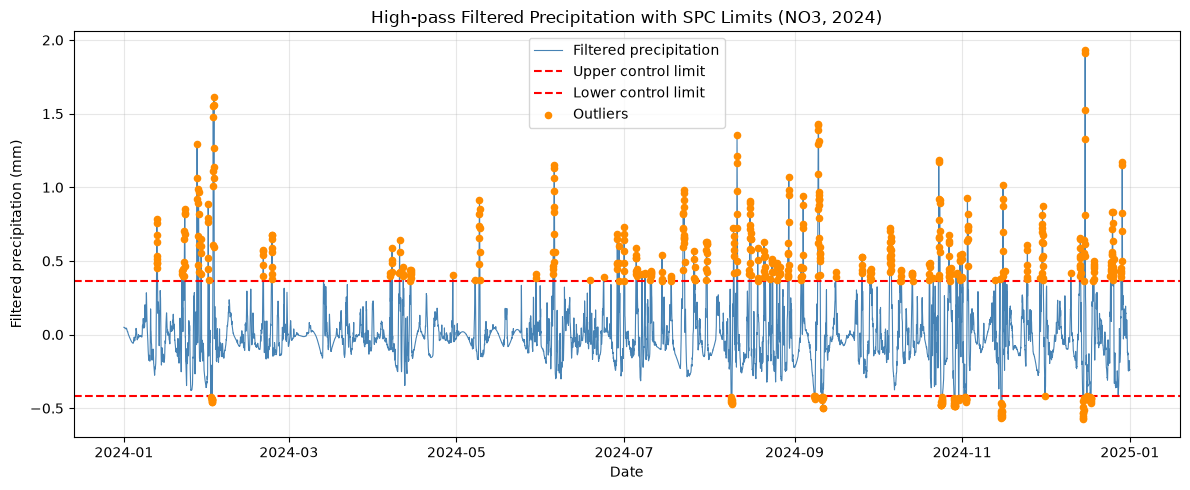

In [17]:
fig, ax = plt.subplots(figsize=(12, 5))

# Plot filtered precipitation
ax.plot(
    weather_no3["date"],
    signal,
    color="steelblue",
    linewidth=0.8,
    label="Filtered precipitation"
)

# Plot SPC boundaries
ax.axhline(ucl, color="red", linestyle="--", label="Upper control limit")
ax.axhline(lcl, color="red", linestyle="--", label="Lower control limit")

# Highlight outliers
ax.scatter(
    weather_no3.loc[outliers, "date"],
    signal[outliers],
    color="darkorange",
    s=20,
    label="Outliers",
    zorder=3
)

ax.set_title("High-pass Filtered Precipitation with SPC Limits (NO3, 2024)")
ax.set_xlabel("Date")
ax.set_ylabel("Filtered precipitation (mm)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

The data is right skewed. The boundaries is set +-3 from the MAD, which is a robust statistic that measures absolute deviations from the median value. Since the data is right skewed it has a number of positive observations which is indicated as outliers ... 

Funtion that take frequency cut-off and number og standard deviatons as parameters and returns the plot and relevant summaries of the outliers

In [28]:
def plot_precipitation_spc(
    df: pd.DataFrame,
    cutoff_period: int = 168,
    n_std: float = 3.0
) -> tuple[Figure, dict]:
    """
    Plot average precipitation with robust SPC boundaries.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame containing date and precipitation columns.
    cutoff_period : int
        Cutoff period in hours (default: 168 = 7 days).
    n_std : float
        Number of standard deviations for SPC boundaries.

    Returns
    -------
    tuple[Figure, dict]
        Matplotlib figure and a summary of detected outliers.
    """

    precipitation = df["precipitation"].to_numpy()
    dates = df["date"]

    # Apply DCT high-pass filtering
    N = len(precipitation)
    W = np.linspace(0, 0.5, N)
    cutoff = 1 / cutoff_period

    dct_signal = dct(precipitation, type=1, norm="forward")
    filtered_dct = dct_signal.copy()
    filtered_dct[W < cutoff] = 0

    filtered = idct(filtered_dct, type=1, norm="forward")

    # Calculate robust statistics from the filtered signal
    median = np.median(filtered)
    mad = np.median(np.abs(filtered - median))
    robust_std = 1.4826 * mad

    ucl = median + n_std * robust_std
    lcl = median - n_std * robust_std

    # Identify outliers using filtered values
    outliers = (filtered > ucl) | (filtered < lcl)

    # Convert SPC limits back to original precipitation scale
    trend = precipitation - filtered
    upper_boundary = trend + ucl
    lower_boundary = trend + lcl

    # Plot original precipitation
    fig, ax = plt.subplots(figsize=(12, 5))

    ax.plot(dates, precipitation, color="steelblue",
            linewidth=0.8, label="Average precipitation")

    ax.plot(dates, upper_boundary, "r--",
            label="Upper control limit")
    ax.plot(dates, lower_boundary, "r--",
            label="Lower control limit")

    ax.scatter(
        dates[outliers],
        precipitation[outliers],
        color="darkorange",
        s=15,
        label="Outliers",
        zorder=3
    )

    ax.set_title("Average Precipitation with SPC Limits (NO3, 2024)")
    ax.set_xlabel("Date")
    ax.set_ylabel("Average precipitation (mm)")
    ax.legend()
    ax.grid(alpha=0.3)

    fig.tight_layout()

    # Short outlier summary
    # Create outlier summary table
    outlier_summary = pd.DataFrame({
        "Metric": [
            "Total observations",
            "Number of outliers",
            "Percentage of outliers (%)",
            "Maximum outlier precipitation (mm)"
        ],
        "Value": [
            len(precipitation),
            int(outliers.sum()),
            round(outliers.mean() * 100, 2),
            round(float(precipitation[outliers].max()), 3)
            if outliers.any() else np.nan
        ]
    })

    return fig, outlier_summary


,Metric,Value
0,Total observations,8784.000
1,Number of outliers,564.000
2,Percentage of outliers (%),6.420
3,Maximum outlier precipitation (mm),2.631


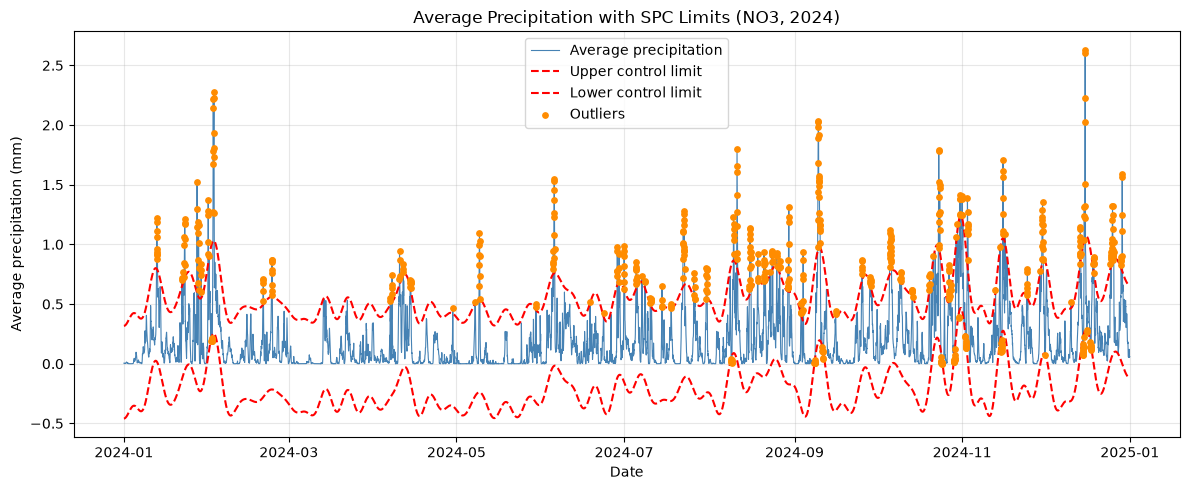

In [32]:
# test the function 
fig, summary = plot_precipitation_spc(weather_no3)

display(summary)
plt.show()

,Metric,Value
0,Total observations,8784.000
1,Number of outliers,1008.000
2,Percentage of outliers (%),11.480
3,Maximum outlier precipitation (mm),2.631


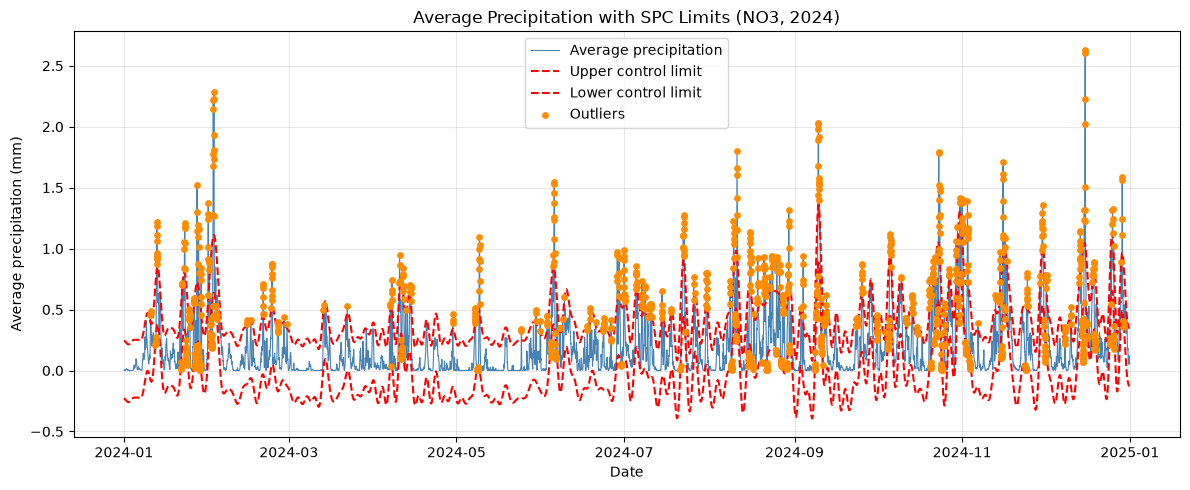

In [30]:
# Test with different parameters
fig, summary = plot_precipitation_spc(
    weather_no3,
    cutoff_period=72,
    n_std=2.5
)

display(summary)
plt.show()

Plot of the average temperature as a function of time.

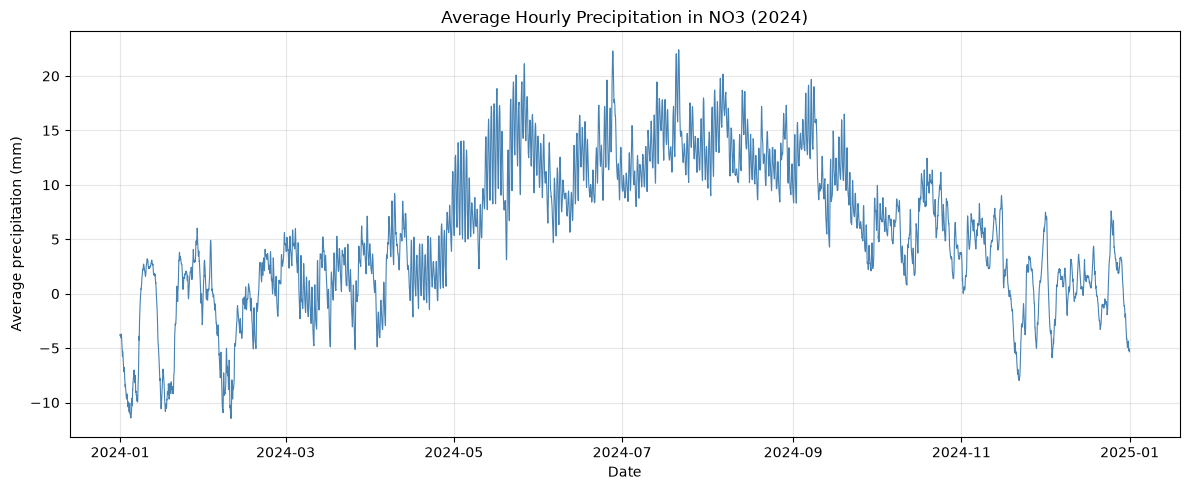

In [34]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    weather_no3["date"],
    weather_no3["temperature_2m"],
    color="steelblue",
    linewidth=0.8
)

ax.set_title("Average Hourly Precipitation in NO3 (2024)")
ax.set_xlabel("Date")
ax.set_ylabel("Average precipitation (mm)")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Indicate anomalies according to the Local Outlier Factor method.

In [39]:
temp2D = weather_no3["temperature_2m"].to_numpy()
temp2D = temp2D.reshape(-1, 1)

lof = LocalOutlierFactor(n_neighbors=20, contamination='auto') # 0.01)
pred_labels = lof.fit_predict(temp2D)
counts = np.bincount(pred_labels+1)
print(counts)
print(counts[0]/sum(counts))

[   5    0 8779]
0.000569216757741348


According to the local outlier factor method there are 5 outliers among the 8779 observations of temperature in area NO3 in 2024. 

Let the proportion of outliers be a parameter defaulting to 1%.
Wrap this in a function that returns the plot and relevant summaries of the outliers, and test the function.

In [40]:
def plot_temperature_lof(
    df: pd.DataFrame,
    contamination: float = 0.01,
    n_neighbors: int = 20
) -> tuple[Figure, pd.DataFrame]:
    """
    Detect temperature outliers using Local Outlier Factor (LOF).

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame containing date and temperature_2m columns.
    contamination : float
        Expected proportion of outliers (default: 0.01).
    n_neighbors : int
        Number of nearest neighbors used by LOF (default: 20).

    Returns
    -------
    tuple[Figure, pd.DataFrame]
        Matplotlib figure and a summary table of detected outliers.
    """

    # Extract temperature as a 2D array
    temp = df[["temperature_2m"]].to_numpy()

    # Apply Local Outlier Factor
    lof = LocalOutlierFactor(
        n_neighbors=n_neighbors,
        contamination=contamination
    )

    pred_labels = lof.fit_predict(temp)

    # Identify outliers
    outliers = pred_labels == -1

    # Plot temperature and highlight outliers
    fig, ax = plt.subplots(figsize=(12, 5))

    ax.plot(
        df["date"],
        df["temperature_2m"],
        color="steelblue",
        linewidth=0.8,
        label="Average temperature"
    )

    ax.scatter(
        df.loc[outliers, "date"],
        df.loc[outliers, "temperature_2m"],
        color="darkorange",
        s=20,
        label="Outliers",
        zorder=3
    )

    ax.set_title("Average Temperature with LOF Outliers (NO3, 2024)")
    ax.set_xlabel("Date")
    ax.set_ylabel("Temperature (°C)")
    ax.legend()
    ax.grid(alpha=0.3)

    fig.tight_layout()

    # Create outlier summary table
    outlier_summary = pd.DataFrame({
        "Metric": [
            "Total observations",
            "Number of outliers",
            "Percentage of outliers (%)",
            "Minimum outlier temperature (°C)",
            "Maximum outlier temperature (°C)"
        ],
        "Value": [
            len(df),
            int(outliers.sum()),
            round(outliers.mean() * 100, 2),
            round(float(temp[outliers].min()), 2)
            if outliers.any() else np.nan,
            round(float(temp[outliers].max()), 2)
            if outliers.any() else np.nan
        ]
    })

    return fig, outlier_summary

,Metric,Value
0,Total observations,8784.00
1,Number of outliers,88.00
2,Percentage of outliers (%),1.00
3,Minimum outlier temperature (°C),-11.47
4,Maximum outlier temperature (°C),20.71


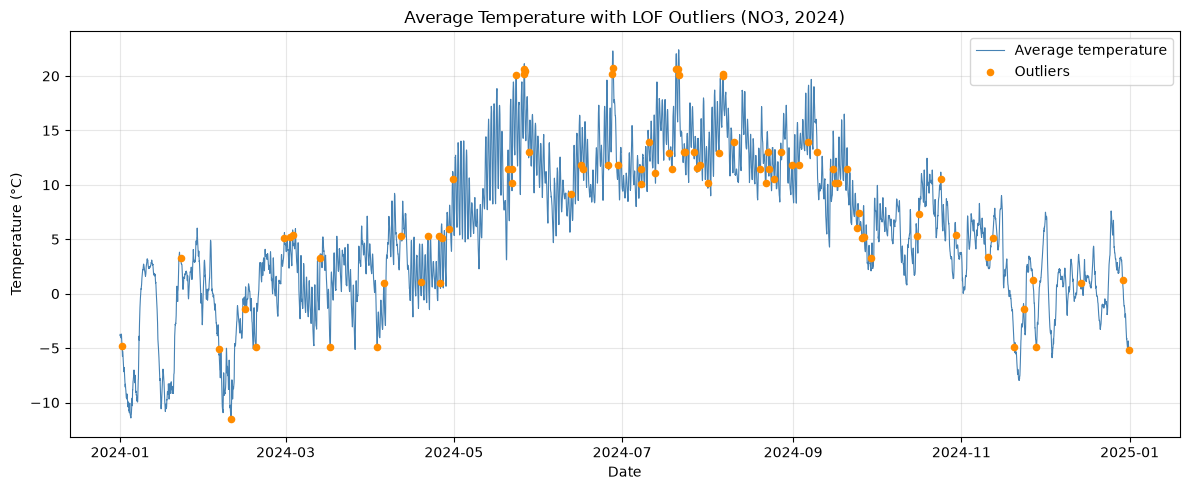

In [41]:
fig, summary = plot_temperature_lof(weather_no3)

display(summary)
plt.show()

,Metric,Value
0,Total observations,8784.00
1,Number of outliers,176.00
2,Percentage of outliers (%),2.00
3,Minimum outlier temperature (°C),-11.47
4,Maximum outlier temperature (°C),20.71


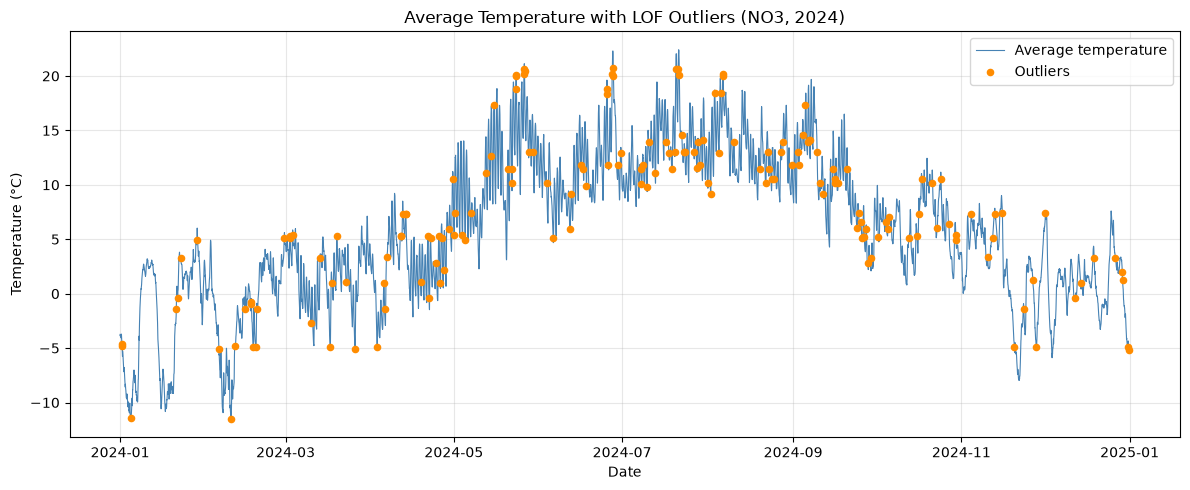

In [42]:
fig, summary = plot_temperature_lof(
    weather_no3,
    contamination=0.02
)

display(summary)
plt.show()

#### Log (description of compulsory work)

- laste ned værdata fra openmeteo - løkke over responses og batchwise 
Kort oppsummert: Du bruker batching for å kunne laste ned dataene uten å sende for store forespørsler, og du looper over responsene fordi hver respons inneholder værdata for én lokasjon. Til slutt kombinerer du dataene og beregner gjennomsnittet for hele regionen.

**Batching:** I download the weather data in batches of 10 locations to avoid sending too many coordinates in a single API request. Sending all 1000 coordinates at once results in a URL that is too long for the server to handle (HTTP 414).

**While loop and error handling:** I use a `while` loop with `try`/`except` to handle API rate limits. If the API returns an error because the number of requests per minute has been exceeded, the program waits 60 seconds before trying again. This allows the download to continue without stopping due to temporary rate-limit errors.


#### Description of AI usage
